# Visual ML Assessment of Meat Freshness from Image-based Quality Indicators

# Step 1:Import Libraries

In [1]:
import pandas as pd
import os
from skimage.transform import resize
from skimage.io import imread
import numpy as np
import matplotlib.pyplot as plt
from skimage import io, transform
from sklearn import preprocessing
import numpy as np
import joblib
import cv2


from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.tree import DecisionTreeClassifier
import seaborn as sns
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.ensemble import RandomForestClassifier


# Step 2:Import Meat Dataset

In [2]:
path = r"C:\Users\Srinitha\OneDrive\Desktop\mini project\Meat freshness"
model_folder = "model"
categories = [d for d in os.listdir(path) if os.path.isdir(os.path.join(path, d))]
categories

['FRESH', 'SPOILED']

# Step 3:Image Processing

In [3]:
X_file = os.path.join(model_folder,"X.txt.npy")
Y_file = os.path.join(model_folder,"Y.txt.npy")
if os.path.exists(X_file) and os.path.exists(Y_file):
    X = np.load(X_file)
    Y = np.load(Y_file)
    print("X and Y arrays loaded successfully.")
else:
    X = [] # input array
    Y = [] # output array
    for root, dirs, directory in os.walk(path):
        for j in range(len(directory)):
            name = os.path.basename(root)
            print(f'Loading category: {dirs}')
            print(name+" "+root+"/"+directory[j])
            if 'Thumbs.db' not in directory[j]:
                img_array = cv2.imread(root+"/"+directory[j])
                img_resized = resize(img_array, (64, 64, 3))
                X.append(img_resized.flatten())
                Y.append(categories.index(name))
    X = np.array(X)
    Y = np.array(Y)
    
    np.save(X_file, X)
    np.save(Y_file, Y)

X and Y arrays loaded successfully.


# Step 4:Seperation of X(input) & Y(target)

In [4]:
df=pd.DataFrame(X)
df

,0,1,2,3,4,5,6,7,8,9,...,12278,12279,12280,12281,12282,12283,12284,12285,12286,12287
0,0.596087,0.674412,0.906265,0.542277,0.603143,0.858254,0.614208,0.686067,0.893549,0.648331,...,0.249142,0.253813,0.273905,0.271170,0.285233,0.305325,0.302589,0.295733,0.315825,0.313089
1,0.596087,0.674412,0.906265,0.542277,0.603143,0.858254,0.614208,0.686067,0.893549,0.648331,...,0.249142,0.253813,0.273905,0.271170,0.285233,0.305325,0.302589,0.295733,0.315825,0.313089
2,0.721512,0.760728,0.827395,0.719844,0.758966,0.825633,0.727051,0.763258,0.829896,0.725302,...,0.777012,0.517218,0.537290,0.706140,0.362488,0.380645,0.578683,0.362058,0.397582,0.582639
3,0.425374,0.431245,0.570155,0.445711,0.442533,0.570944,0.514356,0.500038,0.607160,0.475348,...,0.447783,0.420424,0.433895,0.452752,0.426598,0.452272,0.465142,0.514646,0.533051,0.504968
4,0.736333,0.870805,0.917846,0.713888,0.847353,0.897811,0.645762,0.771918,0.860335,0.586608,...,0.708491,0.432279,0.554110,0.740878,0.443216,0.544046,0.753321,0.315337,0.391621,0.635295
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1355,0.134959,0.228414,0.345352,0.143670,0.236992,0.353984,0.144454,0.231959,0.351370,0.149177,...,0.223744,0.142908,0.186417,0.241535,0.104166,0.172864,0.274383,0.050760,0.146220,0.287056
1356,0.116363,0.207193,0.331357,0.127970,0.221975,0.335329,0.161806,0.256089,0.328473,0.200971,...,0.390833,0.078433,0.211961,0.385970,0.059203,0.182656,0.352739,0.071988,0.187558,0.344083
1357,0.153834,0.247952,0.389128,0.150741,0.244681,0.385810,0.160479,0.248394,0.387560,0.154660,...,0.364189,0.132865,0.229403,0.374459,0.122098,0.223922,0.369056,0.117657,0.219618,0.364716
1358,0.179768,0.263714,0.435235,0.181424,0.268488,0.427985,0.168575,0.260545,0.406277,0.156697,...,0.523777,0.588098,0.578999,0.528272,0.473702,0.452707,0.394890,0.691609,0.657198,0.614901


In [5]:
df['labels']=Y
Y

array([0, 0, 0, ..., 1, 1, 1])

# Step 5:Data Spliting

In [6]:
x_train,x_test,y_train,y_test = train_test_split(X,Y,test_size=0.20,random_state=77)

## User Defined for Performance Evolution

In [7]:
accuracy=[]
precision = []
recall = []
fscore = []
overall_results = []

classwise_results = []

In [1]:
def calculateMetrics(algorithm, predict, testY, labels):

    # Overall metrics
    a = accuracy_score(testY, predict) * 100
    p = precision_score(testY, predict, average='macro') * 100
    r = recall_score(testY, predict, average='macro') * 100
    f = f1_score(testY, predict, average='macro') * 100

    # Save overall metrics
    overall_results.append({
        "Algorithm": algorithm,
        "Accuracy (%)": a,
        "Precision (%)": p,
        "Recall (%)": r,
        "F1 Score (%)": f
    })

    print(f"{algorithm} Accuracy: {a:.2f}")
    print(f"{algorithm} Precision: {p:.2f}")
    print(f"{algorithm} Recall: {r:.2f}")
    print(f"{algorithm} F1 Score: {f:.2f}\n")

    # Classification report & confusion matrix
    report = classification_report(testY, predict, target_names=labels, output_dict=True)
    conf_matrix = confusion_matrix(testY, predict)

    # Class-wise accuracy
    class_accuracy = conf_matrix.diagonal() / conf_matrix.sum(axis=1)

    print(f"{algorithm} Class-wise Metrics:")
    print(f"{'Class':<12}{'Accuracy':<12}{'Precision':<12}{'Recall':<12}{'F1 Score':<12}")

    for i, class_name in enumerate(labels):
        acc = class_accuracy[i] * 100
        prec = report[class_name]['precision'] * 100
        rec = report[class_name]['recall'] * 100
        f1 = report[class_name]['f1-score'] * 100

        print(f"{class_name:<12}{acc:<12.2f}{prec:<12.2f}{rec:<12.2f}{f1:<12.2f}")

        # Save class-wise metrics
        classwise_results.append({
            "Algorithm": algorithm,
            "Class": class_name,
            "Accuracy (%)": acc,
            "Precision (%)": prec,
            "Recall (%)": rec,
            "F1 Score (%)": f1
        })

    # Confusion matrix plot
    plt.figure(figsize=(5, 5))
    sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
                xticklabels=labels, yticklabels=labels)
    plt.title(f"{algorithm} Confusion Matrix")
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.show()


# Step 6:Model Building

## 6.1 Gaussian Naive Bayes Classifier (GNBC Model)

Gaussian NBC Accuracy: 87.13
Gaussian NBC Precision: 87.19
Gaussian NBC Recall: 87.00
Gaussian NBC F1 Score: 87.07

Gaussian NBC Class-wise Metrics:
Class       Accuracy    Precision   Recall      F1 Score    
FRESH       89.51       86.49       89.51       87.97       
SPOILED     84.50       87.90       84.50       86.17       


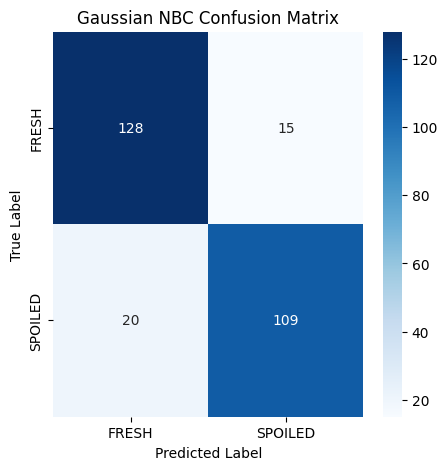

In [9]:
Model_file = os.path.join(model_folder, "Gaussian_NBC_Model.pkl")
if os.path.exists(Model_file):
    nb_classifier = joblib.load(Model_file)
    y_pred = nb_classifier.predict(x_test)
    calculateMetrics("Gaussian NBC", y_pred, y_test, categories)
else:
    nb_classifier = GaussianNB()
    nb_classifier.fit(x_train, y_train)
    joblib.dump(nb_classifier, Model_file)  
    y_pred = nb_classifier.predict(x_test)
    calculateMetrics("Gaussian NBC", y_pred, y_test, categories)

## 6.2 Random Forest Classifier (RFC Model)

RFC Accuracy: 93.75
RFC Precision: 93.86
RFC Recall: 93.64
RFC F1 Score: 93.72

RFC Class-wise Metrics:
Class       Accuracy    Precision   Recall      F1 Score    
FRESH       95.80       92.57       95.80       94.16       
SPOILED     91.47       95.16       91.47       93.28       


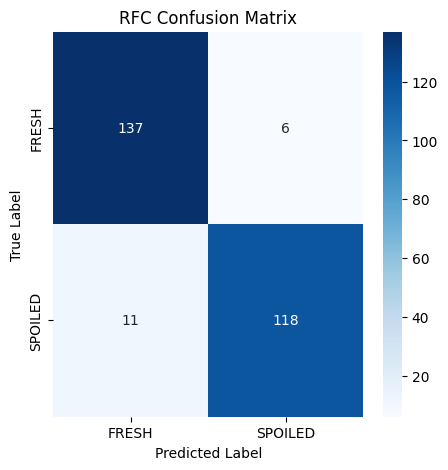

In [10]:
# Check if the pkl file exists
Model_file = os.path.join(model_folder, "Random Forest Classifier_Model.pkl")
if os.path.exists(Model_file):
    rf_classifier = joblib.load(Model_file)
    y_pred = rf_classifier.predict(x_test)
    calculateMetrics("RFC", y_pred, y_test, categories)
else:
    rf_classifier = RandomForestClassifier()
    rf_classifier.fit(x_train, y_train)
    joblib.dump(rf_classifier, Model_file)  
    y_pred = rf_classifier.predict(x_test)
    calculateMetrics("RFC", y_pred, y_test, categories)

## 6.3 Extra Trees Confusion Matrix (ETC Model)

Extra Trees Accuracy: 94.49
Extra Trees Precision: 94.80
Extra Trees Recall: 94.30
Extra Trees F1 Score: 94.45

Extra Trees Class-wise Metrics:
Class       Accuracy    Precision   Recall      F1 Score    
FRESH       97.90       92.11       97.90       94.92       
SPOILED     90.70       97.50       90.70       93.98       


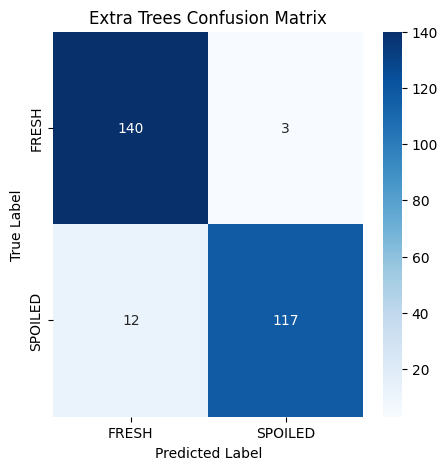

In [11]:
# Check if the pkl file exists
Model_file = os.path.join(model_folder, "EX_Model.pkl")
if os.path.exists(Model_file):
    ex_classifier = joblib.load(Model_file)
    y_pred = ex_classifier.predict(x_test)
    calculateMetrics("Extra Trees", y_pred, y_test, categories)
else:
    ex_classifier = ExtraTreesClassifier()
    ex_classifier.fit(x_train, y_train)
    joblib.dump(ex_classifier, Model_file)  
    y_pred = ex_classifier.predict(x_test)
    calculateMetrics("Extra Trees", y_pred, y_test, categories)

In [12]:
overall_df = pd.DataFrame(overall_results)
overall_df

,Algorithm,Accuracy (%),Precision (%),Recall (%),F1 Score (%)
0,Gaussian NBC,87.132353,87.194856,87.003307,87.069258
1,RFC,93.750000,93.864429,93.638532,93.719354
2,Extra Trees,94.485294,94.802632,94.299886,94.445579


In [13]:
classwise_df = pd.DataFrame(classwise_results)
classwise_df


,Algorithm,Class,Accuracy (%),Precision (%),Recall (%),F1 Score (%)
0,Gaussian NBC,FRESH,89.510490,86.486486,89.510490,87.972509
1,Gaussian NBC,SPOILED,84.496124,87.903226,84.496124,86.166008
2,RFC,FRESH,95.804196,92.567568,95.804196,94.158076
3,RFC,SPOILED,91.472868,95.161290,91.472868,93.280632
4,Extra Trees,FRESH,97.902098,92.105263,97.902098,94.915254
5,Extra Trees,SPOILED,90.697674,97.500000,90.697674,93.975904


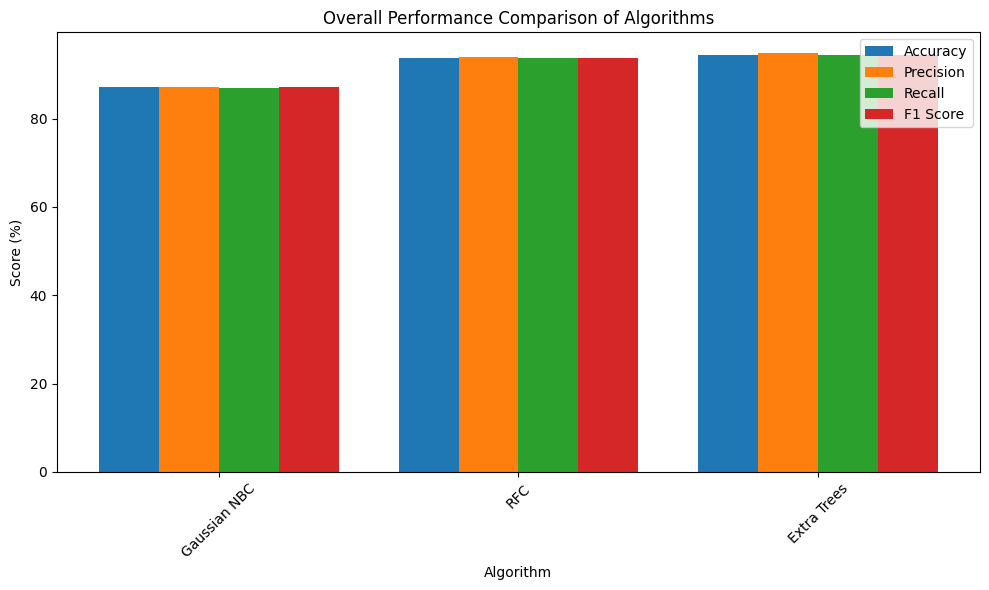

In [14]:
# X locations
x = np.arange(len(overall_df['Algorithm']))
width = 0.2

plt.figure(figsize=(10,6))

plt.bar(x - 1.5*width, overall_df['Accuracy (%)'], width, label='Accuracy')
plt.bar(x - 0.5*width, overall_df['Precision (%)'], width, label='Precision')
plt.bar(x + 0.5*width, overall_df['Recall (%)'], width, label='Recall')
plt.bar(x + 1.5*width, overall_df['F1 Score (%)'], width, label='F1 Score')

plt.xticks(x, overall_df['Algorithm'], rotation=45)
plt.xlabel("Algorithm")
plt.ylabel("Score (%)")
plt.title("Overall Performance Comparison of Algorithms")
plt.legend()
plt.tight_layout()
plt.show()


# Step 7: Final Pridiction of Fresh Data

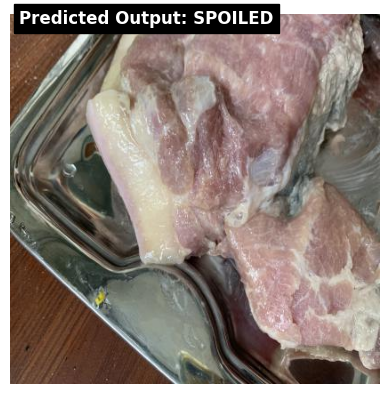

In [15]:
path = r"C:\Users\Srinitha\OneDrive\Desktop\mini project\testImages\SPOILED-2-_JPG.rf.b8182ad123fc4f620131b7ae4c59de03 copy 2.jpg"
img = imread(path)
img_resize = resize(img,(64,64,3))
img_preprocessed = [img_resize.flatten()]
output_number = ex_classifier.predict(img_preprocessed)[0]
output_name = categories[output_number]

plt.imshow(img)
plt.text(10, 10, f'Predicted Output: {output_name}', color='white', fontsize=12, weight='bold', backgroundcolor='black')
plt.axis('off')
plt.show()

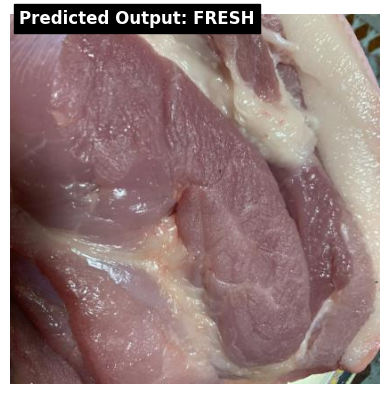

In [16]:
path = r"C:\Users\Srinitha\OneDrive\Desktop\mini project\testImages\FRESH-43-_JPG.rf.992c98b3641f0a86b08e0b50d0fa1f68.jpg"
img = imread(path)
img_resize = resize(img,(64,64,3))
img_preprocessed = [img_resize.flatten()]
output_number = ex_classifier.predict(img_preprocessed)[0]
output_name = categories[output_number]

plt.imshow(img)
plt.text(10, 10, f'Predicted Output: {output_name}', color='white', fontsize=12, weight='bold', backgroundcolor='black')
plt.axis('off')
plt.show()